In [20]:
from huggingface_hub import login
from dotenv import load_dotenv
import os
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

load_dotenv()

login(token=os.getenv("HUGGING_FACE_TOKEN"))

In [21]:
data_repo_name = "mrdbourke/learn_hf_food_not_food_image_captions"
model_repo_name = "distilbert/distilbert-base-uncased"

In [22]:
from datasets import load_dataset

dataset = load_dataset(path = data_repo_name, num_proc=4, cache_dir="data/")

In [23]:
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 250
    })
})

In [24]:
len(dataset['train'])

250

In [25]:
import random

random_indexes = random.sample(range(len(dataset['train'])), k = 5)
samples = dataset['train'][random_indexes]
for text, label in zip(samples['text'], samples['label']):
    print(f"{text} -> {label}")

Set of spatulas kept in a holder -> not_food
Mouthwatering paneer tikka masala, featuring juicy paneer in a rich tomato-based sauce, garnished with fresh coriander leaves. -> food
Pair of reading glasses left open on a book -> not_food
Set of board games stacked on a shelf -> not_food
Two handfuls of bananas in a fruit bowl with grapes on the side, the fruit bowl is blue -> food


In [26]:
ids_to_labels = {idx:label for idx, label in enumerate(dataset['train'].unique('label')[::-1])}
labels_to_ids = {label:idx for idx, label in enumerate(dataset['train'].unique('label')[::-1])}
print(ids_to_labels)
print(labels_to_ids)

{0: 'not_food', 1: 'food'}
{'not_food': 0, 'food': 1}


In [27]:
def encode_label(example):
    example['label'] = labels_to_ids[example['label']]
    return example

label_encoded_dataset = dataset['train'].map(encode_label)
samples = label_encoded_dataset[random_indexes]
for text, label in zip(samples['text'], samples['label']):
    print(f"{text} -> {label}")

Set of spatulas kept in a holder -> 0
Mouthwatering paneer tikka masala, featuring juicy paneer in a rich tomato-based sauce, garnished with fresh coriander leaves. -> 1
Pair of reading glasses left open on a book -> 0
Set of board games stacked on a shelf -> 0
Two handfuls of bananas in a fruit bowl with grapes on the side, the fruit bowl is blue -> 1


In [28]:
dataset = label_encoded_dataset.train_test_split(test_size=0.2,)
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 200
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 50
    })
})

In [29]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(model_repo_name, cache_dir="tokenizer/")

print(f"Vocab size: {tokenizer.vocab_size}")

Vocab size: 30522


In [30]:
def encode_data(example):
    return tokenizer(example['text'], padding=True, truncation=True)

tokenized_data = dataset.map(encode_data, batched=True, batch_size=1000)

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/50 [00:00<?, ? examples/s]

In [31]:
tokenized_data

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 200
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 50
    })
})

In [32]:
import evaluate

accuracy_config = evaluate.load('accuracy', cache_dir='evaluate')
accuracy_config.compute(predictions=[0, 1, 1, 0], references=[0, 1, 0, 1])

{'accuracy': 0.5}

In [33]:
import torch
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(model_repo_name, cache_dir='model/', num_labels=2)
model

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [34]:
from typing import Tuple
import numpy as np

def compute_accuracy(preds_and_labels:Tuple[np.array, np.array]):
    preds = preds_and_labels[0]
    references = preds_and_labels[1]
    if len(preds.shape) >=2:
        preds = np.argmax(preds, axis=1)
    return accuracy_config.compute(predictions=preds, references=references)

In [35]:
from pathlib import Path

models_dir = Path("checkpoints") # creating a path
models_dir.mkdir(exist_ok=True) # checking if it exists or we create it

model_save_name = Path("food_v_not_food-distil-bert-text-classifier")

model_save_path = Path(models_dir, model_save_name)
print(model_save_path)

checkpoints\food_v_not_food-distil-bert-text-classifier


In [36]:
from transformers import TrainingArguments, Trainer

training_arguments = TrainingArguments(output_dir=model_save_path, # path to save checkpoints
                                       per_device_train_batch_size=64, # per device train batch size
                                       per_device_eval_batch_size=64, # per device eval batch size
                                       learning_rate = 0.0001, # learning rate
                                       use_cpu=False, # to use gpu
                                       num_train_epochs=10, # number of train epochs
                                       eval_strategy='epoch', # evaluate model at every epoch
                                       save_strategy='epoch', # save model at every epoch
                                       save_total_limit=2, # save upto 2 models
                                       load_best_model_at_end=True,
                                       seed=42,
                                       logging_strategy='epoch',
                                       report_to='none'
                                       )

training_arguments


TrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=None,
dataloader_drop_last=False,
dataloader_in_order=True,
dataloader_multiprocessing_context=None,
dataloader_num_workers=0,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_static_graph=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=True,
do_predict=False,
do_train=False,
enable_jit_checkpoint=False,
eval_accumulation_steps=None,
eval_delay=0,
eval_do_concat_batches=True,
eval_on_start

In [37]:
trainer = Trainer(model=model,
                           train_dataset=tokenized_data['train'],
                           eval_dataset=tokenized_data['test'],
                           args=training_arguments,
                           compute_metrics=compute_accuracy,
                           processing_class=tokenizer)
trainer

In [38]:
results = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.449156,0.138089,0.980000
2,0.084457,0.022902,1.000000
3,0.016773,0.008239,1.000000
4,0.007121,0.004398,1.000000
5,0.003974,0.002912,1.000000
6,0.002913,0.002214,1.000000
7,0.002395,0.001844,1.000000
8,0.001925,0.001648,1.000000
9,0.001938,0.001549,1.000000
10,0.001663,0.001516,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [42]:
print(results.metrics)

{'train_runtime': 15.4656, 'train_samples_per_second': 129.319, 'train_steps_per_second': 2.586, 'total_flos': 18110777160000.0, 'train_loss': 0.057231557334307584, 'epoch': 10.0}


In [43]:
trainer.save_model(output_dir=model_save_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
trainer.state.log_history

[{'loss': 0.4491559863090515,
  'grad_norm': 2.441362142562866,
  'learning_rate': 9.250000000000001e-05,
  'epoch': 1.0,
  'step': 4},
 {'eval_loss': 0.1380893886089325,
  'eval_accuracy': 0.98,
  'eval_runtime': 0.0469,
  'eval_samples_per_second': 1065.28,
  'eval_steps_per_second': 21.306,
  'epoch': 1.0,
  'step': 4},
 {'loss': 0.08445680141448975,
  'grad_norm': 0.5324384570121765,
  'learning_rate': 8.25e-05,
  'epoch': 2.0,
  'step': 8},
 {'eval_loss': 0.02290169894695282,
  'eval_accuracy': 1.0,
  'eval_runtime': 0.0402,
  'eval_samples_per_second': 1242.875,
  'eval_steps_per_second': 24.857,
  'epoch': 2.0,
  'step': 8},
 {'loss': 0.016772694885730743,
  'grad_norm': 0.15139295160770416,
  'learning_rate': 7.25e-05,
  'epoch': 3.0,
  'step': 12},
 {'eval_loss': 0.008239183574914932,
  'eval_accuracy': 1.0,
  'eval_runtime': 0.0399,
  'eval_samples_per_second': 1253.798,
  'eval_steps_per_second': 25.076,
  'epoch': 3.0,
  'step': 12},
 {'loss': 0.007121182978153229,
  'grad_

In [48]:
trainer.state.log_history[:-1]

[{'loss': 0.4491559863090515,
  'grad_norm': 2.441362142562866,
  'learning_rate': 9.250000000000001e-05,
  'epoch': 1.0,
  'step': 4},
 {'eval_loss': 0.1380893886089325,
  'eval_accuracy': 0.98,
  'eval_runtime': 0.0469,
  'eval_samples_per_second': 1065.28,
  'eval_steps_per_second': 21.306,
  'epoch': 1.0,
  'step': 4},
 {'loss': 0.08445680141448975,
  'grad_norm': 0.5324384570121765,
  'learning_rate': 8.25e-05,
  'epoch': 2.0,
  'step': 8},
 {'eval_loss': 0.02290169894695282,
  'eval_accuracy': 1.0,
  'eval_runtime': 0.0402,
  'eval_samples_per_second': 1242.875,
  'eval_steps_per_second': 24.857,
  'epoch': 2.0,
  'step': 8},
 {'loss': 0.016772694885730743,
  'grad_norm': 0.15139295160770416,
  'learning_rate': 7.25e-05,
  'epoch': 3.0,
  'step': 12},
 {'eval_loss': 0.008239183574914932,
  'eval_accuracy': 1.0,
  'eval_runtime': 0.0399,
  'eval_samples_per_second': 1253.798,
  'eval_steps_per_second': 25.076,
  'epoch': 3.0,
  'step': 12},
 {'loss': 0.007121182978153229,
  'grad_

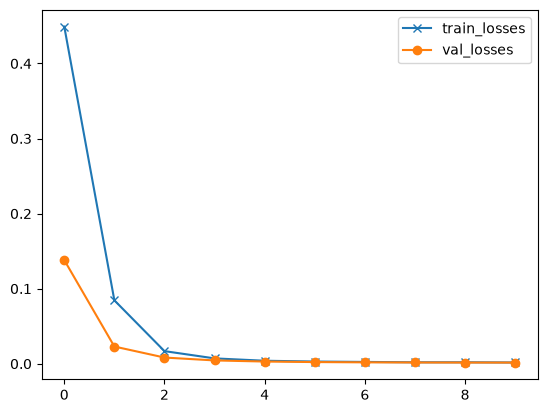

In [54]:
import matplotlib.pyplot as plt

train_losses = []
val_losses = []

for run in trainer.state.log_history[:-1]:
    if 'loss' in run:
        train_losses.append(run.get('loss'))
    else:
        val_losses.append(run.get('eval_loss'))

plt.plot(train_losses, label='train_losses', marker='x')
plt.plot(val_losses, label='val_losses', marker='o')
plt.legend()
plt.show()

In [55]:
model_upload_url = trainer.push_to_hub(commit_message="pushing my first model", token=os.getenv("HF_TOKEN"))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [56]:
model_upload_url

CommitInfo(commit_url='https://huggingface.co/AJ700/food_v_not_food-distil-bert-text-classifier/commit/4293570f1eb6b4819bb94ccd9d8509348072755a', commit_message='pushing my first model', commit_description='', oid='4293570f1eb6b4819bb94ccd9d8509348072755a', pr_url=None, repo_url=RepoUrl('https://huggingface.co/AJ700/food_v_not_food-distil-bert-text-classifier', endpoint='https://huggingface.co', repo_type='model', repo_id='AJ700/food_v_not_food-distil-bert-text-classifier'), pr_revision=None, pr_num=None)

In [57]:
preds = trainer.predict(test_dataset=tokenized_data['test'])

In [61]:
preds.metrics

{'test_loss': 0.0015158300520852208,
 'test_accuracy': 1.0,
 'test_runtime': 0.1599,
 'test_samples_per_second': 312.707,
 'test_steps_per_second': 6.254}

In [75]:
print(torch.softmax(torch.tensor(preds.predictions), dim=1))

tensor([[0.0017, 0.9983],
        [0.9989, 0.0011],
        [0.0017, 0.9983],
        [0.9990, 0.0010],
        [0.9989, 0.0011],
        [0.0017, 0.9983],
        [0.9989, 0.0011],
        [0.9989, 0.0011],
        [0.0017, 0.9983],
        [0.0017, 0.9983],
        [0.0017, 0.9983],
        [0.0017, 0.9983],
        [0.9989, 0.0011],
        [0.0017, 0.9983],
        [0.0018, 0.9982],
        [0.9989, 0.0011],
        [0.0017, 0.9983],
        [0.9988, 0.0012],
        [0.0017, 0.9983],
        [0.0017, 0.9983],
        [0.0017, 0.9983],
        [0.0017, 0.9983],
        [0.9989, 0.0011],
        [0.9989, 0.0011],
        [0.0017, 0.9983],
        [0.0017, 0.9983],
        [0.0018, 0.9982],
        [0.9989, 0.0011],
        [0.0017, 0.9983],
        [0.9989, 0.0011],
        [0.0017, 0.9983],
        [0.0017, 0.9983],
        [0.0017, 0.9983],
        [0.9990, 0.0010],
        [0.0017, 0.9983],
        [0.0018, 0.9982],
        [0.0017, 0.9983],
        [0.0017, 0.9983],
        [0.9

In [73]:
print(torch.argmax(torch.tensor(preds.predictions), dim=1).tolist())

[1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1]


In [72]:
print(list(tokenized_data['test']['label']))

[1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1]
